In [2]:
print("Kalvikannan")
print("24BAD052")

Kalvikannan
24BAD052


### Part A: Dataset preparation

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (60000, 28, 28) Test: (10000, 28, 28)


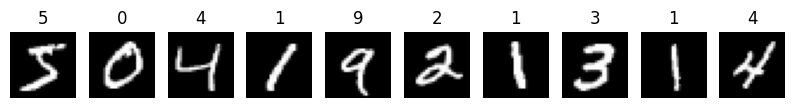

After flattening: (60000, 784) (10000, 784)


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
print("Train:", x_train.shape, "Test:", x_test.shape)

plt.figure(figsize=(10, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(y_train[i])
    plt.axis("off")
plt.show()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train.reshape(len(x_train), 784)
x_test = x_test.reshape(len(x_test), 784)
print("After flattening:", x_train.shape, x_test.shape)

### Part B: Encoder and decoder

In [4]:
print("Roll No: 24BAD052")

latent_dim = 32

inp = keras.Input(shape=(784,))
x = layers.Dense(128, activation="relu")(inp)
latent = layers.Dense(latent_dim, activation="relu")(x)

dec_in = keras.Input(shape=(latent_dim,))
y = layers.Dense(128, activation="relu")(dec_in)
out = layers.Dense(784, activation="sigmoid")(y)

encoder = keras.Model(inp, latent, name="encoder")
decoder = keras.Model(dec_in, out, name="decoder")

autoencoder = keras.Model(inp, decoder(encoder(inp)), name="autoencoder")

encoder.summary()
decoder.summary()
autoencoder.summary()

Roll No: 24BAD052


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

 Non-trainable params: 0 (0.00 B)

... (6 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 32)             │       104,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 784)            │       105,360 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

### Part C: Compile and train

Roll No: 24BAD052
Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 0.2313 - val_loss: 0.1558
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1392 - val_loss: 0.1241
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1183 - val_loss: 0.1113
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1092 - val_loss: 0.1055
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1046 - val_loss: 0.1016
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1015 - val_loss: 0.0990
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0993 - val_loss: 0.0973
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0978 - val_loss: 0.0958
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0966 - val_loss: 0.0950
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0955 - val_loss: 0.0939


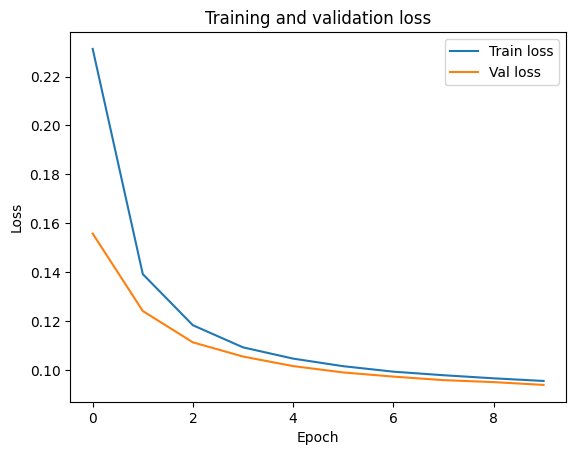

In [5]:
print("Roll No: 24BAD052")

autoencoder.compile(optimizer="adam", loss="binary_crossentropy")

history = autoencoder.fit(x_train, x_train,
                          epochs=10,
                          batch_size=256,
                          shuffle=True,
                          validation_data=(x_test, x_test))

plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and validation loss")
plt.legend()
plt.show()

### Part D: Latent features and reconstruction

Roll No: 24BAD052
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Original dimension: 784
Latent dimension: 32


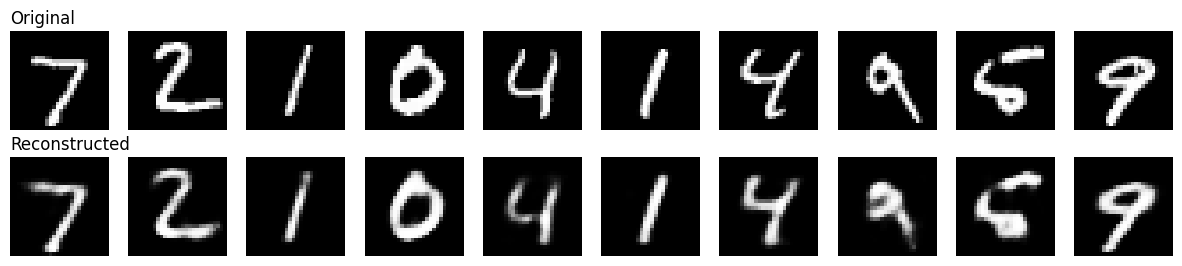

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Test BCE loss: 0.09385990351438522
Test MSE: 0.010516549


In [6]:
print("Roll No: 24BAD052")

encoded = encoder.predict(x_test)
decoded = decoder.predict(encoded)

print("Original dimension:", x_test.shape[1])
print("Latent dimension:", encoded.shape[1])

n = 10
plt.figure(figsize=(15, 3))
for i in range(n):
    plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.title("Original", loc="left")

    plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.title("Reconstructed", loc="left")
plt.show()

test_loss = autoencoder.evaluate(x_test, x_test, verbose=0)
mse = np.mean((x_test - autoencoder.predict(x_test)) ** 2)
print("Test BCE loss:", test_loss)
print("Test MSE:", mse)

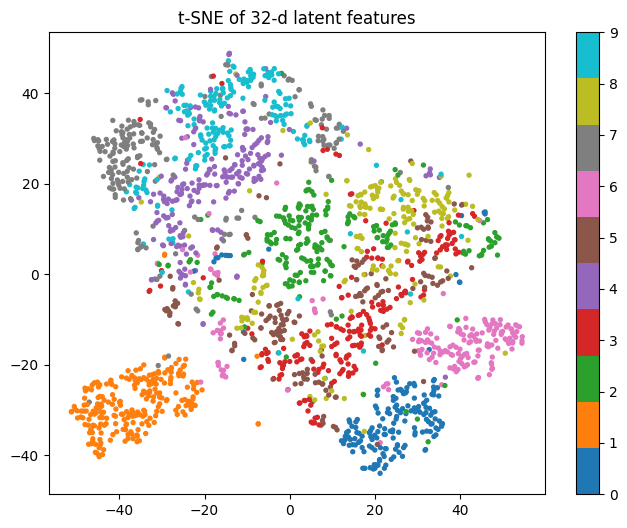

In [7]:
from sklearn.manifold import TSNE

sample = encoded[:2000]
labels = y_test[:2000]

tsne = TSNE(n_components=2, random_state=42)
points = tsne.fit_transform(sample)

plt.figure(figsize=(8, 6))
sc = plt.scatter(points[:, 0], points[:, 1], c=labels, cmap="tab10", s=8)
plt.colorbar(sc)
plt.title("t-SNE of 32-d latent features")
plt.show()

In [8]:
autoencoder.save("autoencoder_mnist.keras")
encoder.save("encoder_mnist.keras")
decoder.save("decoder_mnist.keras")